Proyecto Olist ML
Predicción de retrasos logísticos y segmentación de clientes

Institución: Universidad de Cundinamarca

Programa: Ingeniería de Sistemas

Asignatura: Ciencia de Datos

Integrantes: Juan David Aguilar Páez y Nicolas Mauricio Vasquez

Cuadernillo: 05 - segmentacion clientes

# Segmentación de clientes con RFM y K-Means

## Proyecto Olist — Aprendizaje no supervisado

### Objetivo
Analizar el comportamiento de compra de los clientes mediante
indicadores RFM (recencia, frecuencia y valor monetario) para
identificar posibles segmentos utilizando el algoritmo K-Means.

Este análisis complementa el modelado supervisado realizado
anteriormente, pero no utiliza la variable objetivo `retraso`.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path

ruta = Path("../data/raw")

print("Entorno preparado")

Entorno preparado


## 1. Identificación de clientes

Antes de calcular los indicadores RFM, revisamos los identificadores
de clientes para determinar cuántos compradores diferentes existen
y cuántos realizaron más de una compra.

In [3]:
clientes = pd.read_csv(
    ruta / "olist_customers_dataset.csv"
)

print("Dimensiones:", clientes.shape)

print(
    "Clientes únicos:",
    clientes["customer_unique_id"].nunique()
)

print(
    "Identificadores de pedido:",
    clientes["customer_id"].nunique()
)

clientes.head()

Dimensiones: (99441, 5)
Clientes únicos: 96096
Identificadores de pedido: 99441


,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,14409,franca,SP
1,18955e83d337fd6b2def6b18a428ac77,290c77bc529b7ac935b93aa66c333dc3,9790,sao bernardo do campo,SP
2,4e7b3e00288586ebd08712fdd0374a03,060e732b5b29e8181a18229c7b0b2b5e,1151,sao paulo,SP
3,b2b6027bc5c5109e529d4dc6358b12c3,259dac757896d24d7702b9acbbff3f3c,8775,mogi das cruzes,SP
4,4f2d8ab171c80ec8364f7c12e35b23ad,345ecd01c38d18a9036ed96c73b8d066,13056,campinas,SP


In [4]:
frecuencia_clientes = clientes["customer_unique_id"].value_counts()

print(
    "Compradores con un registro:",
    (frecuencia_clientes == 1).sum()
)

print(
    "Compradores con varios registros:",
    (frecuencia_clientes > 1).sum()
)

print(
    "Máximo de registros por comprador:",
    frecuencia_clientes.max()
)

print("\nDistribución:")
print(frecuencia_clientes.value_counts().sort_index())

Compradores con un registro: 93099
Compradores con varios registros: 2997
Máximo de registros por comprador: 17

Distribución:
count
1     93099
2      2745
3       203
4        30
5         8
6         6
7         3
9         1
17        1
Name: count, dtype: int64


## 2. Preparación de pedidos para el análisis RFM

Relacionamos los pedidos con sus compradores mediante
`customer_id`, para posteriormente calcular la recencia,
frecuencia y valor monetario de cada cliente.

In [6]:
pedidos = pd.read_csv(
    ruta / "olist_orders_dataset.csv",
    parse_dates=["order_purchase_timestamp"]
)

pedidos_clientes = pedidos.merge(
    clientes[["customer_id", "customer_unique_id"]],
    on="customer_id",
    how="left",
    validate="many_to_one"
)

print("Pedidos originales:", len(pedidos))
print("Pedidos relacionados:", len(pedidos_clientes))

print(
    "Compradores sin identificar:",
    pedidos_clientes["customer_unique_id"].isna().sum()
)

print("\nEstados de los pedidos:")
print(pedidos_clientes["order_status"].value_counts())

Pedidos originales: 99441
Pedidos relacionados: 99441
Compradores sin identificar: 0

Estados de los pedidos:
order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64


In [7]:
compras_rfm = pedidos_clientes[
    pedidos_clientes["order_status"] == "delivered"
].copy()

print("Pedidos entregados:", len(compras_rfm))

print(
    "Compradores únicos:",
    compras_rfm["customer_unique_id"].nunique()
)

print(
    "Pedidos duplicados:",
    compras_rfm["order_id"].duplicated().sum()
)

print(
    "Fechas de compra faltantes:",
    compras_rfm["order_purchase_timestamp"].isna().sum()
)

print(
    "Primera compra:",
    compras_rfm["order_purchase_timestamp"].min()
)

print(
    "Última compra:",
    compras_rfm["order_purchase_timestamp"].max()
)


Pedidos entregados: 96478
Compradores únicos: 93358
Pedidos duplicados: 0
Fechas de compra faltantes: 0
Primera compra: 2016-09-15 12:16:38
Última compra: 2018-08-29 15:00:37


## 3. Construcción de indicadores RFM

### Recencia y frecuencia

La recencia representa los días transcurridos desde la última
compra de cada cliente hasta el 30 de agosto de 2018.

La frecuencia corresponde al número de pedidos entregados
realizados por cada comprador durante el período analizado.

In [8]:
fecha_referencia = pd.Timestamp("2018-08-30")

rf_clientes = (
    compras_rfm.groupby("customer_unique_id")
    .agg(
        ultima_compra=("order_purchase_timestamp", "max"),
        frecuencia=("order_id", "nunique")
    )
    .reset_index()
)

rf_clientes["recencia_dias"] = (
    fecha_referencia - rf_clientes["ultima_compra"]
).dt.days

print("Compradores analizados:", len(rf_clientes))

print("\nEstadísticas de recencia y frecuencia:")
print(
    rf_clientes[["recencia_dias", "frecuencia"]].describe()
)

rf_clientes.head()

Compradores analizados: 93358

Estadísticas de recencia y frecuencia:
       recencia_dias    frecuencia
count   93358.000000  93358.000000
mean      237.478888      1.033420
std       152.595050      0.209097
min         0.000000      1.000000
25%       114.000000      1.000000
50%       218.000000      1.000000
75%       346.000000      1.000000
max       713.000000     15.000000


,customer_unique_id,ultima_compra,frecuencia,recencia_dias
0,0000366f3b9a7992bf8c76cfdf3221e2,2018-05-10 10:56:27,1,111
1,0000b849f77a49e4a4ce2b2a4ca5be3f,2018-05-07 11:11:27,1,114
2,0000f46a3911fa3c0805444483337064,2017-03-10 21:05:03,1,537
3,0000f6ccb0745a6a4b88665a16c9f078,2017-10-12 20:29:41,1,321
4,0004aac84e0df4da2b147fca70cf8255,2017-11-14 19:45:42,1,288


### Preparación del valor monetario

El indicador monetario representa el valor total de los pagos
registrados para los pedidos entregados de cada comprador.

Antes de calcularlo, revisamos la tabla de pagos porque un pedido
puede contener varios registros de pago.

In [10]:
pagos = pd.read_csv(
    ruta / "olist_order_payments_dataset.csv"
)

print("Registros de pagos:", len(pagos))

print(
    "Pedidos distintos con pagos:",
    pagos["order_id"].nunique()
)

print(
    "Pedidos con varios registros de pago:",
    (pagos["order_id"].value_counts() > 1).sum()
)

print(
    "Valores de pago faltantes:",
    pagos["payment_value"].isna().sum()
)

print("\nEstadísticas de los pagos:")
print(pagos["payment_value"].describe())

pagos.head()

Registros de pagos: 103886
Pedidos distintos con pagos: 99440
Pedidos con varios registros de pago: 2961
Valores de pago faltantes: 0

Estadísticas de los pagos:
count    103886.000000
mean        154.100380
std         217.494064
min           0.000000
25%          56.790000
50%         100.000000
75%         171.837500
max       13664.080000
Name: payment_value, dtype: float64


,order_id,payment_sequential,payment_type,payment_installments,payment_value
0,b81ef226f3fe1789b1e8b2acac839d17,1,credit_card,8,99.33
1,a9810da82917af2d9aefd1278f1dcfa0,1,credit_card,1,24.39
2,25e8ea4e93396b6fa0d3dd708e76c1bd,1,credit_card,1,65.71
3,ba78997921bbcdc1373bb41e913ab953,1,credit_card,8,107.78
4,42fdf880ba16b47b59251dd489d4441a,1,credit_card,2,128.45


### Cálculo del valor monetario por pedido

Agrupamos los registros de pago mediante `order_id` y sumamos
sus valores para obtener el importe total registrado por pedido.

Este procedimiento permite conservar los pagos múltiples sin
duplicar los pedidos durante la construcción del indicador
monetario (M).

In [11]:
pagos_por_pedido = (
    pagos.groupby("order_id", as_index=False)
    .agg(
        valor_total_pedido=("payment_value", "sum")
    )
)

compras_con_pagos = compras_rfm.merge(
    pagos_por_pedido,
    on="order_id",
    how="left",
    validate="one_to_one"
)

print("Pedidos entregados:", len(compras_rfm))
print("Pedidos después de la unión:", len(compras_con_pagos))

print(
    "Pedidos entregados sin pago:",
    compras_con_pagos["valor_total_pedido"].isna().sum()
)

print("\nEstadísticas del valor por pedido:")
print(compras_con_pagos["valor_total_pedido"].describe())

compras_con_pagos[
    ["order_id", "customer_unique_id", "valor_total_pedido"]
].head()

Pedidos entregados: 96478
Pedidos después de la unión: 96478
Pedidos entregados sin pago: 1

Estadísticas del valor por pedido:
count    96477.000000
mean       159.856357
std        218.813144
min          9.590000
25%         61.880000
50%        105.280000
75%        176.330000
max      13664.080000
Name: valor_total_pedido, dtype: float64


,order_id,customer_unique_id,valor_total_pedido
0,e481f51cbdc54678b7cc49136f2d6af7,7c396fd4830fd04220f754e42b4e5bff,38.71
1,53cdb2fc8bc7dce0b6741e2150273451,af07308b275d755c9edb36a90c618231,141.46
2,47770eb9100c2d0c44946d9cf07ec65d,3a653a41f6f9fc3d2a113cf8398680e8,179.12
3,949d5b44dbf5de918fe9c16f97b45f8a,7c142cf63193a1473d2e66489a9ae977,72.20
4,ad21c59c0840e6cb83a9ceb5573f8159,72632f0f9dd73dfee390c9b22eb56dd6,28.62


## 4. Construcción de la tabla RFM

Se integran los indicadores de recencia (R), frecuencia (F)
y valor monetario (M) para cada comprador.

Se excluyen los pedidos entregados sin información de pago,
evitando imputar importes desconocidos.

Los tres indicadores se calculan sobre el mismo conjunto
de pedidos, utilizando `customer_unique_id`.

In [13]:
# Conservar únicamente pedidos entregados con pago registrado
compras_rfm_validas = compras_con_pagos.dropna(
    subset=["valor_total_pedido"]
).copy()

# Calcular los tres indicadores por comprador
rfm_clientes = (
    compras_rfm_validas
    .groupby("customer_unique_id")
    .agg(
        ultima_compra=("order_purchase_timestamp", "max"),
        recuento_pedidos=("order_id", "nunique"),
        gasto_total=("valor_total_pedido", "sum")
    )
    .reset_index()
)

# Calcular recencia respecto a la fecha histórica
rfm_clientes["recencia_dias"] = (
    fecha_referencia - rfm_clientes["ultima_compra"]
).dt.days

# Renombrar la frecuencia
rfm_clientes = rfm_clientes.rename(
    columns={"recuento_pedidos": "frecuencia"}
)

# Seleccionar columnas finales
rfm_clientes = rfm_clientes[
    [
        "customer_unique_id",
        "recencia_dias",
        "frecuencia",
        "gasto_total"
    ]
]

print("Pedidos válidos:", len(compras_rfm_validas))
print("Compradores en RFM:", len(rfm_clientes))

print("\nValores faltantes:")
print(rfm_clientes.isna().sum())

print("\nEstadísticas RFM:")
print(
    rfm_clientes[
        ["recencia_dias", "frecuencia", "gasto_total"]
    ].describe()
)

rfm_clientes.head()

Pedidos válidos: 96477
Compradores en RFM: 93357

Valores faltantes:
customer_unique_id    0
recencia_dias         0
frecuencia            0
gasto_total           0
dtype: int64

Estadísticas RFM:
       recencia_dias    frecuencia   gasto_total
count   93357.000000  93357.000000  93357.000000
mean      237.473794      1.033420    165.198772
std       152.587931      0.209099    226.314579
min         0.000000      1.000000      9.590000
25%       114.000000      1.000000     63.060000
50%       218.000000      1.000000    107.780000
75%       346.000000      1.000000    182.560000
max       695.000000     15.000000  13664.080000


,customer_unique_id,recencia_dias,frecuencia,gasto_total
0,0000366f3b9a7992bf8c76cfdf3221e2,111,1,141.90
1,0000b849f77a49e4a4ce2b2a4ca5be3f,114,1,27.19
2,0000f46a3911fa3c0805444483337064,537,1,86.22
3,0000f6ccb0745a6a4b88665a16c9f078,321,1,43.62
4,0004aac84e0df4da2b147fca70cf8255,288,1,196.89


## 5. Análisis exploratorio de los indicadores RFM

Se examinan las distribuciones de recencia, frecuencia y
valor monetario para identificar concentraciones, asimetrías
y posibles valores extremos.

Este análisis permitirá determinar las transformaciones
necesarias antes de aplicar el algoritmo K-Means.

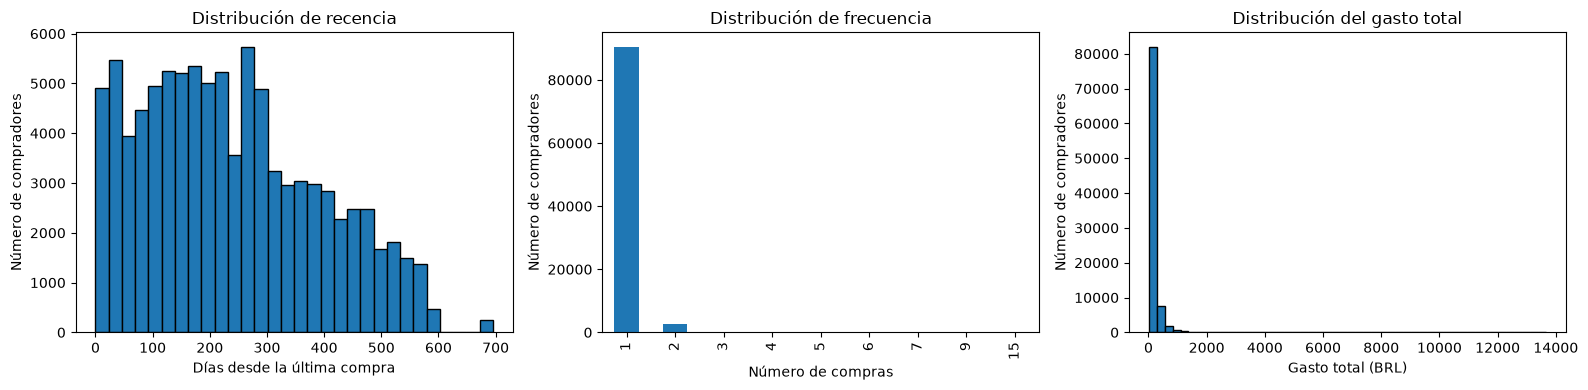

In [15]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))

# Recencia
ax[0].hist(
    rfm_clientes["recencia_dias"],
    bins=30,
    edgecolor="black"
)
ax[0].set_title("Distribución de recencia")
ax[0].set_xlabel("Días desde la última compra")
ax[0].set_ylabel("Número de compradores")

# Frecuencia
rfm_clientes["frecuencia"].value_counts().sort_index().plot(
    kind="bar",
    ax=ax[1]
)
ax[1].set_title("Distribución de frecuencia")
ax[1].set_xlabel("Número de compras")
ax[1].set_ylabel("Número de compradores")

# Valor monetario
ax[2].hist(
    rfm_clientes["gasto_total"],
    bins=50,
    edgecolor="black"
)
ax[2].set_title("Distribución del gasto total")
ax[2].set_xlabel("Gasto total (BRL)")
ax[2].set_ylabel("Número de compradores")

plt.tight_layout()
plt.show()

## 6. Transformación de los indicadores RFM

Las distribuciones originales muestran asimetría y diferencias
importantes de escala.

Aplicamos la transformación logarítmica `log1p` para reducir
la influencia de valores elevados, conservando todos los
compradores del conjunto de datos.

Posteriormente evaluaremos el efecto de esta transformación
antes de realizar el escalado para K-Means.

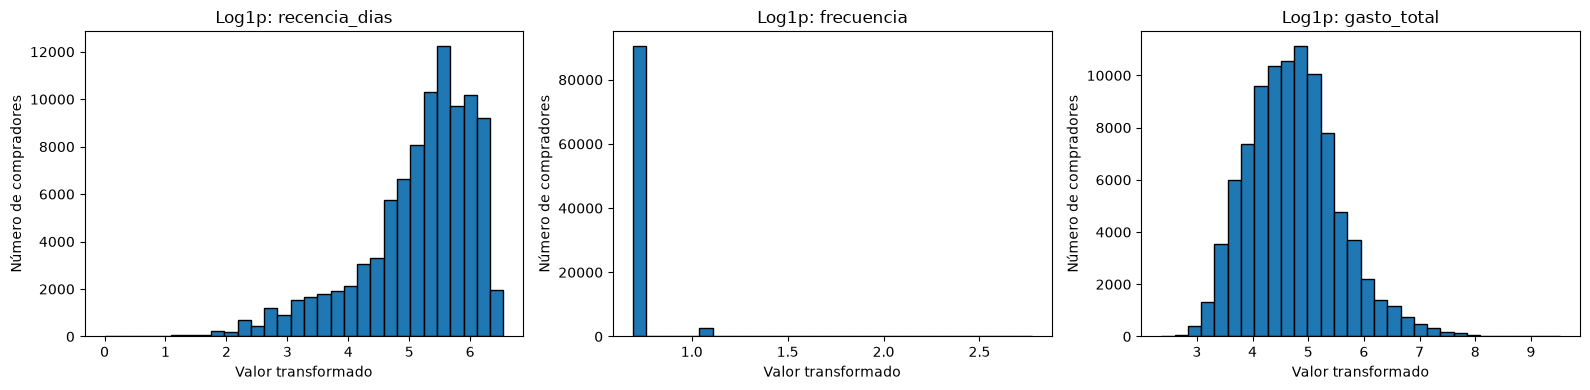

Estadísticas después de log1p:
       recencia_dias    frecuencia   gasto_total
count   93357.000000  93357.000000  93357.000000
mean        5.161257      0.706198      4.729149
std         0.940940      0.076683      0.808359
min         0.000000      0.693147      2.359910
25%         4.744932      0.693147      4.159820
50%         5.389072      0.693147      4.689327
75%         5.849325      0.693147      5.212542
max         6.545350      2.772589      9.522599


In [17]:
variables_rfm = [
    "recencia_dias",
    "frecuencia",
    "gasto_total"
]

rfm_log = np.log1p(
    rfm_clientes[variables_rfm]
)

fig, ax = plt.subplots(1, 3, figsize=(16, 4))

for i, variable in enumerate(variables_rfm):
    ax[i].hist(
        rfm_log[variable],
        bins=30,
        edgecolor="black"
    )

    ax[i].set_title(f"Log1p: {variable}")
    ax[i].set_xlabel("Valor transformado")
    ax[i].set_ylabel("Número de compradores")

plt.tight_layout()
plt.show()

print("Estadísticas después de log1p:")
print(rfm_log.describe())

### Evaluación de la frecuencia de compra

Antes de aplicar K-Means, analizamos qué porcentaje de
compradores realizó una sola compra y qué porcentaje
realizó varias.

Esta comprobación permite determinar si la frecuencia
aporta suficiente información para construir segmentos
de clientes o si conviene utilizarla principalmente
para interpretar los grupos obtenidos.

In [18]:
conteo_frecuencia = (
    rfm_clientes["frecuencia"]
    .value_counts()
    .sort_index()
)

porcentaje_una_compra = (
    rfm_clientes["frecuencia"].eq(1).mean() * 100
)

porcentaje_recurrentes = (
    rfm_clientes["frecuencia"].gt(1).mean() * 100
)

print("Distribución de frecuencia:")
print(conteo_frecuencia)

print(
    f"\nCompradores con una compra: "
    f"{porcentaje_una_compra:.2f}%"
)

print(
    f"Compradores con varias compras: "
    f"{porcentaje_recurrentes:.2f}%"
)

Distribución de frecuencia:
frecuencia
1     90556
2      2573
3       181
4        28
5         9
6         5
7         3
9         1
15        1
Name: count, dtype: int64

Compradores con una compra: 97.00%
Compradores con varias compras: 3.00%


## 7. Escalado de variables para K-Means

Se preparan dos conjuntos de características para comparar
estrategias de segmentación:

- RFM: recencia, frecuencia y gasto total.
- RM: recencia y gasto total.

Ambos conjuntos utilizan la transformación logarítmica
calculada anteriormente y posteriormente se estandarizan
con StandardScaler.

El objetivo es comparar si incluir la frecuencia aporta
información útil a la formación de los segmentos.

In [19]:
from sklearn.preprocessing import StandardScaler

# Variables para cada alternativa
variables_rfm = [
    "recencia_dias",
    "frecuencia",
    "gasto_total"
]

variables_rm = [
    "recencia_dias",
    "gasto_total"
]

# Crear escaladores independientes
escalador_rfm = StandardScaler()
escalador_rm = StandardScaler()

# Escalar las variables transformadas
X_rfm = escalador_rfm.fit_transform(
    rfm_log[variables_rfm]
)

X_rm = escalador_rm.fit_transform(
    rfm_log[variables_rm]
)

print("Dimensiones RFM:", X_rfm.shape)
print("Dimensiones RM:", X_rm.shape)

print("\nMedias RFM:")
print(X_rfm.mean(axis=0).round(4))

print("\nDesviaciones estándar RFM:")
print(X_rfm.std(axis=0).round(4))

print("\nMedias RM:")
print(X_rm.mean(axis=0).round(4))

print("\nDesviaciones estándar RM:")
print(X_rm.std(axis=0).round(4))

Dimensiones RFM: (93357, 3)
Dimensiones RM: (93357, 2)

Medias RFM:
[-0.  0.  0.]

Desviaciones estándar RFM:
[1. 1. 1.]

Medias RM:
[-0.  0.]

Desviaciones estándar RM:
[1. 1.]


## 8. Primer modelo de segmentación con K-Means

Se entrena un modelo inicial de K-Means utilizando tres grupos
para comprender su funcionamiento y verificar los resultados.

Se utiliza inicialmente la alternativa RM (recencia y gasto
monetario), conservando la frecuencia para analizar
posteriormente los segmentos obtenidos.

El número de grupos es provisional y será evaluado
en experimentos posteriores.

In [20]:
from sklearn.cluster import KMeans

# Crear el modelo inicial con tres grupos
kmeans_rm = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

# Entrenar el modelo y obtener los grupos
grupos_rm = kmeans_rm.fit_predict(X_rm)

# Crear una copia de la tabla para analizar los resultados
segmentos_rm = rfm_clientes.copy()
segmentos_rm["segmento"] = grupos_rm

print("Cantidad de compradores por segmento:")
print(segmentos_rm["segmento"].value_counts().sort_index())

print("\nInercia del modelo:")
print(kmeans_rm.inertia_)

print("\nCentroides estandarizados:")
print(kmeans_rm.cluster_centers_)


Cantidad de compradores por segmento:
segmento
0    16380
1    43791
2    33186
Name: count, dtype: int64

Inercia del modelo:
75088.80389100497

Centroides estandarizados:
[[-1.73867825 -0.08097604]
 [ 0.40928418 -0.69221689]
 [ 0.3174707   0.95675041]]


## 9. Interpretación de los segmentos iniciales

Se analizan las características originales de los compradores
asignados a cada segmento de K-Means.

Aunque el modelo utiliza recencia y gasto monetario, también
se examina la frecuencia de compra para interpretar el
comportamiento de los grupos.

Se utilizan medianas para reducir la influencia de valores
monetarios extremos.

In [21]:
resumen_segmentos = (
    segmentos_rm.groupby("segmento")
    .agg(
        compradores=("customer_unique_id", "count"),
        recencia_mediana=("recencia_dias", "median"),
        frecuencia_mediana=("frecuencia", "median"),
        gasto_mediano=("gasto_total", "median"),
        gasto_promedio=("gasto_total", "mean")
    )
    .round(2)
)

resumen_segmentos["porcentaje"] = (
    resumen_segmentos["compradores"]
    / len(segmentos_rm) * 100
).round(2)

print("Perfil de los segmentos:")
display(resumen_segmentos)

Perfil de los segmentos:


,compradores,recencia_mediana,frecuencia_mediana,gasto_mediano,gasto_promedio,porcentaje
segmento,,,,,,
0,16380,37.0,1.0,106.32,136.92,17.55
1,43791,270.0,1.0,67.13,69.71,46.91
2,33186,251.0,1.0,206.87,305.16,35.55


## 10. Evaluación del número de segmentos

### Método del codo

Se entrenan modelos K-Means con diferentes números de grupos
para analizar cómo cambia la inercia.

El método del codo ayuda a identificar un punto a partir del
cual aumentar la cantidad de segmentos produce mejoras cada
vez menores.

Esta evaluación no determina por sí sola el número óptimo
de grupos, por lo que posteriormente se complementará con
otras métricas y la interpretación de los segmentos.

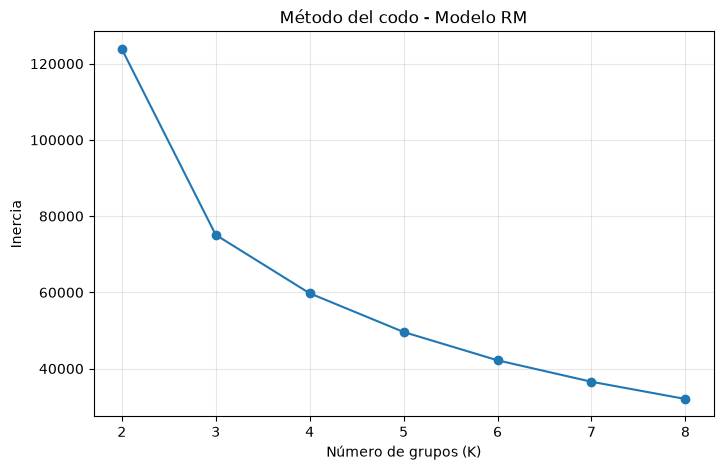

Inercia por número de grupos:
K=2: 123854.74
K=3: 75088.80
K=4: 59759.69
K=5: 49607.16
K=6: 42179.96
K=7: 36550.25
K=8: 32027.74


In [22]:
valores_k = range(2, 9)
inercias_rm = []

for k in valores_k:
    modelo = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    modelo.fit(X_rm)
    inercias_rm.append(modelo.inertia_)

plt.figure(figsize=(8, 5))

plt.plot(
    list(valores_k),
    inercias_rm,
    marker="o"
)

plt.title("Método del codo - Modelo RM")
plt.xlabel("Número de grupos (K)")
plt.ylabel("Inercia")
plt.xticks(list(valores_k))
plt.grid(alpha=0.3)

plt.show()

print("Inercia por número de grupos:")

for k, inercia in zip(valores_k, inercias_rm):
    print(f"K={k}: {inercia:.2f}")

### Evaluación mediante Silhouette Score

Se complementa el método del codo con el coeficiente de silueta,
que permite evaluar la cohesión y separación de los grupos.

Se comparan valores de K entre 2 y 8 utilizando el modelo RM.

Para reducir el costo computacional, se utiliza una muestra
reproducible de 3.000 compradores para evaluar cada modelo.

K=2: Silhouette Score = 0.4004
K=3: Silhouette Score = 0.3931
K=4: Silhouette Score = 0.3501
K=5: Silhouette Score = 0.3503
K=6: Silhouette Score = 0.3421
K=7: Silhouette Score = 0.3408
K=8: Silhouette Score = 0.3299


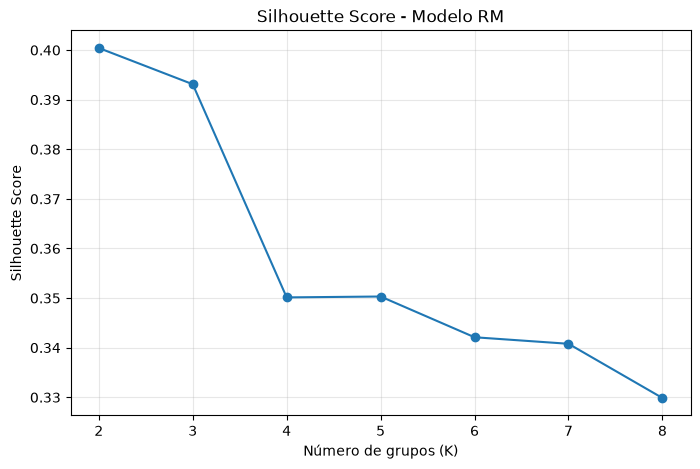

In [23]:
from sklearn.metrics import silhouette_score

resultados_silueta_rm = []

for k in range(2, 9):
    modelo = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    etiquetas = modelo.fit_predict(X_rm)

    puntuacion = silhouette_score(
        X_rm,
        etiquetas,
        sample_size=3000,
        random_state=42
    )

    resultados_silueta_rm.append(puntuacion)

    print(f"K={k}: Silhouette Score = {puntuacion:.4f}")

plt.figure(figsize=(8, 5))

plt.plot(
    range(2, 9),
    resultados_silueta_rm,
    marker="o"
)

plt.title("Silhouette Score - Modelo RM")
plt.xlabel("Número de grupos (K)")
plt.ylabel("Silhouette Score")
plt.xticks(range(2, 9))
plt.grid(alpha=0.3)

plt.show()

### Comparación de segmentaciones con K=2 y K=3

El coeficiente de silueta favorece ligeramente a K=2,
mientras que K=3 permite identificar tres perfiles de
compradores en términos de recencia y gasto monetario.

Se comparan ambas alternativas utilizando las variables
originales para evaluar su interpretabilidad.

La selección final considerará tanto las métricas
matemáticas como la utilidad de los segmentos obtenidos.

In [24]:
# Entrenar K-Means con dos segmentos
kmeans_rm_2 = KMeans(
    n_clusters=2,
    random_state=42,
    n_init=10
)

grupos_rm_2 = kmeans_rm_2.fit_predict(X_rm)

# Asociar los grupos a los compradores
segmentos_rm_2 = rfm_clientes.copy()
segmentos_rm_2["segmento"] = grupos_rm_2

# Resumir el comportamiento de cada segmento
resumen_rm_2 = (
    segmentos_rm_2.groupby("segmento")
    .agg(
        compradores=("customer_unique_id", "count"),
        recencia_mediana=("recencia_dias", "median"),
        frecuencia_mediana=("frecuencia", "median"),
        gasto_mediano=("gasto_total", "median"),
        gasto_promedio=("gasto_total", "mean")
    )
    .round(2)
)

resumen_rm_2["porcentaje"] = (
    resumen_rm_2["compradores"]
    / len(segmentos_rm_2) * 100
).round(2)

print("MODELO RM - K=2")
display(resumen_rm_2)

print("\nMODELO RM - K=3")
display(resumen_segmentos)

MODELO RM - K=2


,compradores,recencia_mediana,frecuencia_mediana,gasto_mediano,gasto_promedio,porcentaje
segmento,,,,,,
0,19863,44.0,1.0,112.42,173.11,21.28
1,73494,270.0,1.0,106.87,163.06,78.72



MODELO RM - K=3


,compradores,recencia_mediana,frecuencia_mediana,gasto_mediano,gasto_promedio,porcentaje
segmento,,,,,,
0,16380,37.0,1.0,106.32,136.92,17.55
1,43791,270.0,1.0,67.13,69.71,46.91
2,33186,251.0,1.0,206.87,305.16,35.55


## 11. Comparación con el modelo RFM completo

Se entrena K-Means utilizando recencia, frecuencia y gasto
monetario, previamente transformados y estandarizados.

El objetivo es investigar cómo cambia la segmentación al
incorporar la frecuencia de compra.

Se utiliza inicialmente K=3 para comparar los resultados
con el modelo RM de tres segmentos.

In [25]:
# Entrenar K-Means con las tres variables RFM
kmeans_rfm_3 = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

grupos_rfm_3 = kmeans_rfm_3.fit_predict(X_rfm)

# Asociar los grupos a los compradores
segmentos_rfm_3 = rfm_clientes.copy()
segmentos_rfm_3["segmento"] = grupos_rfm_3

# Calcular el perfil de cada segmento
resumen_rfm_3 = (
    segmentos_rfm_3.groupby("segmento")
    .agg(
        compradores=("customer_unique_id", "count"),
        recencia_mediana=("recencia_dias", "median"),
        frecuencia_mediana=("frecuencia", "median"),
        gasto_mediano=("gasto_total", "median"),
        gasto_promedio=("gasto_total", "mean")
    )
    .round(2)
)

resumen_rfm_3["porcentaje"] = (
    resumen_rfm_3["compradores"]
    / len(segmentos_rfm_3) * 100
).round(2)

print("MODELO RFM - K=3")
display(resumen_rfm_3)

print("\nInercia RFM:", round(kmeans_rfm_3.inertia_, 2))

MODELO RFM - K=3


,compradores,recencia_mediana,frecuencia_mediana,gasto_mediano,gasto_promedio,porcentaje
segmento,,,,,,
0,19093,44.0,1.0,108.43,165.62,20.45
1,71463,270.0,1.0,104.87,159.47,76.55
2,2801,199.0,2.0,225.55,308.59,3.00



Inercia RFM: 129260.21


### Verificación de compradores recurrentes por segmento

Se verifica qué proporción de compradores realizó más
de una compra dentro de cada segmento del modelo RFM.

Esto permite comprobar si K-Means separó realmente a
los compradores recurrentes y evita interpretar los
segmentos únicamente a partir de sus medianas.

In [26]:
# Identificar compradores con más de una compra
segmentos_rfm_3["recurrente"] = (
    segmentos_rfm_3["frecuencia"] > 1
)

# Contar compradores recurrentes y no recurrentes
tabla_recurrencia = pd.crosstab(
    segmentos_rfm_3["segmento"],
    segmentos_rfm_3["recurrente"]
)

tabla_recurrencia = tabla_recurrencia.rename(
    columns={
        False: "una_compra",
        True: "varias_compras"
    }
)

print("Compradores por segmento y recurrencia:")
display(tabla_recurrencia)

print("\nPorcentaje de recurrentes por segmento:")
print(
    (
        segmentos_rfm_3
        .groupby("segmento")["recurrente"]
        .mean() * 100
    ).round(2)
)

Compradores por segmento y recurrencia:


recurrente,una_compra,varias_compras
segmento,,
0,19093,0
1,71463,0
2,0,2801



Porcentaje de recurrentes por segmento:
segmento
0      0.0
1      0.0
2    100.0
Name: recurrente, dtype: float64


## 12. Evaluación del modelo RFM completo

El modelo RFM con K=3 separó los 2.801 compradores
recurrentes en un segmento exclusivo.

Se calcula el coeficiente de silueta para evaluar la
cohesión y separación de los grupos obtenidos.

La comparación con RM se considera exploratoria, ya
que ambos modelos utilizan diferentes conjuntos de
características.

In [27]:
from sklearn.metrics import silhouette_score

silueta_rfm_3 = silhouette_score(
    X_rfm,
    grupos_rfm_3,
    sample_size=3000,
    random_state=42
)

silueta_rm_3 = silhouette_score(
    X_rm,
    grupos_rm,
    sample_size=3000,
    random_state=42
)

print("Silhouette Score - Comparación K=3")
print(f"RM:  {silueta_rm_3:.4f}")
print(f"RFM: {silueta_rfm_3:.4f}")

Silhouette Score - Comparación K=3
RM:  0.3931
RFM: 0.4120


## 13. Estabilidad de los modelos K-Means

Se evalúa la estabilidad de los modelos RM y RFM con K=3
mediante diferentes semillas de inicialización.

Se utiliza el Adjusted Rand Index (ARI) para comparar
las asignaciones de los compradores entre ejecuciones.

El objetivo es verificar si los segmentos son consistentes
ante cambios en la inicialización del algoritmo.

In [28]:
from sklearn.metrics import adjusted_rand_score

semillas = [0, 21, 42, 100, 123]

resultados_estabilidad = []

for nombre, X in [("RM", X_rm), ("RFM", X_rfm)]:

    etiquetas_base = KMeans(
        n_clusters=3,
        random_state=42,
        n_init=10
    ).fit_predict(X)

    for semilla in semillas:
        etiquetas = KMeans(
            n_clusters=3,
            random_state=semilla,
            n_init=10
        ).fit_predict(X)

        ari = adjusted_rand_score(
            etiquetas_base,
            etiquetas
        )

        resultados_estabilidad.append({
            "modelo": nombre,
            "semilla": semilla,
            "ARI": ari
        })

estabilidad = pd.DataFrame(resultados_estabilidad)

print("Estabilidad por inicialización:")
display(
    estabilidad.pivot(
        index="semilla",
        columns="modelo",
        values="ARI"
    ).round(4)
)

Estabilidad por inicialización:


modelo,RFM,RM
semilla,,
0,0.9961,0.9935
21,0.9949,0.9951
42,1.0000,1.0000
100,0.9949,0.9837
123,1.0000,0.9845


## 14. Visualización de los segmentos RM

Se representan los segmentos obtenidos mediante K-Means
con tres grupos, utilizando las variables originales
de recencia y gasto monetario.

La visualización permite observar cómo se distribuyen
los compradores y facilita la interpretación de los
perfiles identificados.

Para mejorar la legibilidad, se utiliza una muestra
reproducible de compradores.


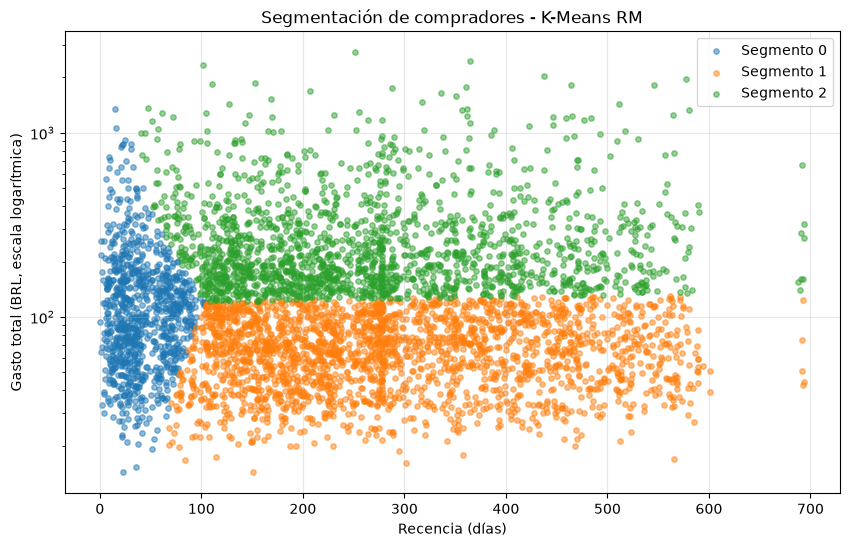

In [29]:
# Seleccionar una muestra para visualizar
muestra_segmentos = segmentos_rm.sample(
    n=5000,
    random_state=42
)

plt.figure(figsize=(10, 6))

for segmento in sorted(muestra_segmentos["segmento"].unique()):

    datos = muestra_segmentos[
        muestra_segmentos["segmento"] == segmento
    ]

    plt.scatter(
        datos["recencia_dias"],
        datos["gasto_total"],
        label=f"Segmento {segmento}",
        alpha=0.5,
        s=15
    )

plt.yscale("log")

plt.title("Segmentación de compradores - K-Means RM")
plt.xlabel("Recencia (días)")
plt.ylabel("Gasto total (BRL, escala logarítmica)")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

## 15. Comparación de perfiles de segmentación

Se comparan los perfiles de los modelos RM y RFM con K=3
mediante sus valores medianos de recencia, frecuencia
y gasto monetario.

El objetivo es identificar qué características distinguen
a los segmentos y cómo cambia su interpretación al incluir
la frecuencia de compra.

Los segmentos de ambos modelos se interpretan por sus
características, ya que sus etiquetas numéricas no
representan categorías equivalentes.

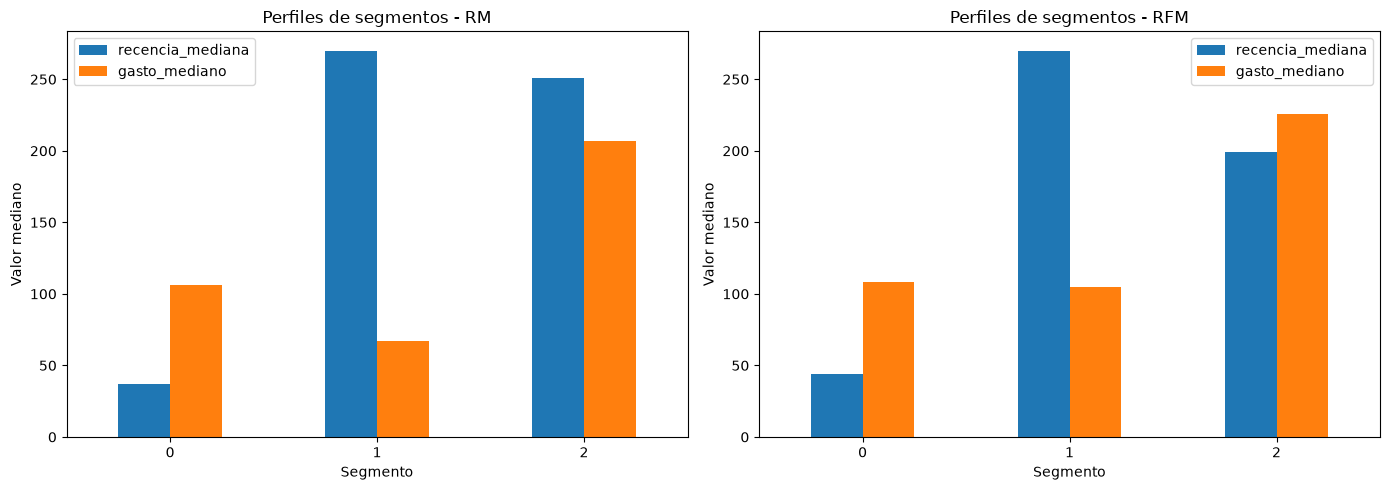

In [30]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))

# Perfil del modelo RM
resumen_segmentos[
    ["recencia_mediana", "gasto_mediano"]
].plot(
    kind="bar",
    ax=ax[0]
)

ax[0].set_title("Perfiles de segmentos - RM")
ax[0].set_xlabel("Segmento")
ax[0].set_ylabel("Valor mediano")
ax[0].tick_params(axis="x", rotation=0)

# Perfil del modelo RFM
resumen_rfm_3[
    ["recencia_mediana", "gasto_mediano"]
].plot(
    kind="bar",
    ax=ax[1]
)

ax[1].set_title("Perfiles de segmentos - RFM")
ax[1].set_xlabel("Segmento")
ax[1].set_ylabel("Valor mediano")
ax[1].tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.show()

### Comparación visual mediante mapas de calor

Se representan los perfiles de los modelos RM y RFM
mediante mapas de calor.

Cada variable se normaliza visualmente entre los segmentos
del mismo modelo, evitando comparar directamente magnitudes
con unidades diferentes.

Los valores mostrados conservan sus unidades originales:
días, compras y reales brasileños.

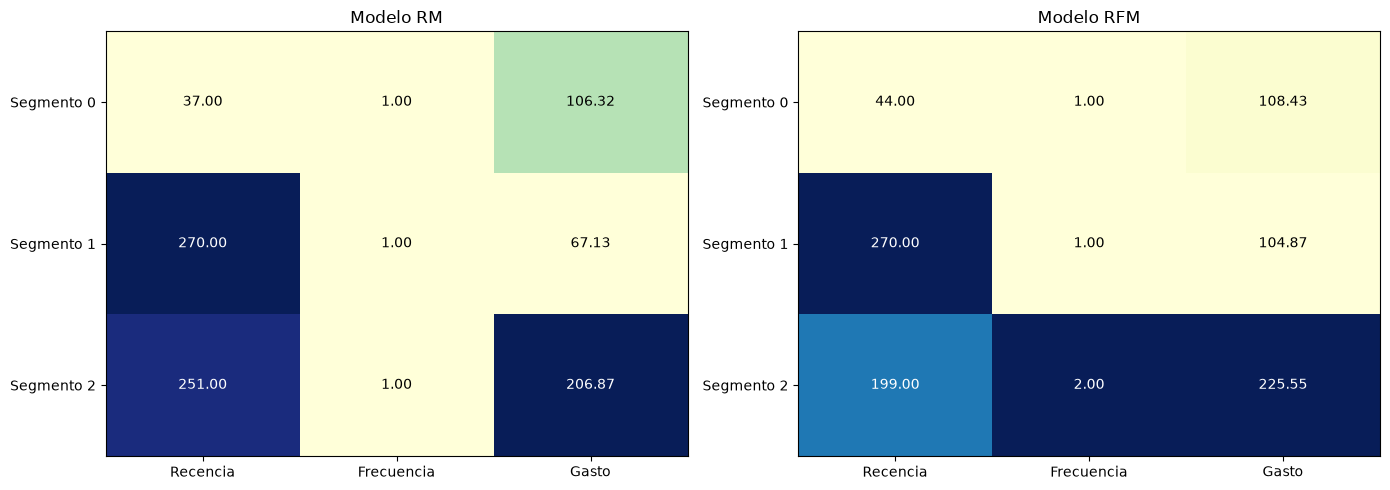

In [32]:
# Variables para comparar
columnas = [
    "recencia_mediana",
    "frecuencia_mediana",
    "gasto_mediano"
]

# Preparar los perfiles
perfil_rm = resumen_segmentos[columnas]
perfil_rfm = resumen_rfm_3[columnas]

fig, ax = plt.subplots(1, 2, figsize=(14, 5))

for eje, perfil, titulo in zip(
    ax,
    [perfil_rm, perfil_rfm],
    ["Modelo RM", "Modelo RFM"]
):
    # Escalado visual independiente por columna
    minimo = perfil.min()
    rango = (perfil.max() - minimo).replace(0, 1)

    perfil_visual = (perfil - minimo) / rango

    imagen = eje.imshow(
        perfil_visual,
        cmap="YlGnBu",
        aspect="auto",
        vmin=0,
        vmax=1
    )

    eje.set_title(titulo)
    eje.set_xticks(range(len(columnas)))
    eje.set_xticklabels(
        ["Recencia", "Frecuencia", "Gasto"]
    )

    eje.set_yticks(range(len(perfil)))
    eje.set_yticklabels(
        [f"Segmento {i}" for i in perfil.index]
    )

    # Mostrar los valores originales
    for i in range(len(perfil)):
        for j in range(len(columnas)):
            valor = perfil.iloc[i, j]

            eje.text(
                j, i, f"{valor:.2f}",
                ha="center",
                va="center",
                color="white" if perfil_visual.iloc[i, j] > 0.5 else "black"
            )

plt.tight_layout()
plt.show()

## 16. Análisis de recurrencia en los segmentos RM

Se examina la distribución de los compradores recurrentes
dentro de los segmentos del modelo RM con K=3.

Aunque la frecuencia no intervino en la formación de estos
grupos, se utiliza como variable externa para evaluar
su composición.

Esta comprobación permitirá complementar la comparación
entre los modelos RM y RFM.

In [33]:
# Identificar compradores recurrentes en el modelo RM
segmentos_rm["recurrente"] = (
    segmentos_rm["frecuencia"] > 1
)

# Contar compradores por segmento
recurrencia_rm = pd.crosstab(
    segmentos_rm["segmento"],
    segmentos_rm["recurrente"]
).rename(
    columns={
        False: "una_compra",
        True: "varias_compras"
    }
)

print("Distribución de recurrencia en RM:")
display(recurrencia_rm)

# Calcular porcentaje de recurrentes dentro de cada segmento
porcentaje_recurrentes_rm = (
    segmentos_rm.groupby("segmento")["recurrente"]
    .mean() * 100
).round(2)

print("\nPorcentaje de recurrentes por segmento:")
print(porcentaje_recurrentes_rm)

print(
    "\nTotal de compradores recurrentes:",
    recurrencia_rm["varias_compras"].sum()
)

Distribución de recurrencia en RM:


recurrente,una_compra,varias_compras
segmento,,
0,15916,464
1,43398,393
2,31242,1944



Porcentaje de recurrentes por segmento:
segmento
0    2.83
1    0.90
2    5.86
Name: recurrente, dtype: float64

Total de compradores recurrentes: 2801


## 17. Exportación de los resultados

Se conserva el modelo RM con K=3 como segmentación principal,
debido a su capacidad para diferenciar compradores según
recencia y gasto monetario.

El modelo RFM con K=3 se mantiene como alternativa
complementaria para analizar la recurrencia.

Se exportan ambas asignaciones de segmentos y sus perfiles
estadísticos para facilitar la reproducibilidad del análisis.

In [34]:
# Crear carpeta de resultados
ruta_resultados = Path("../resultados")
ruta_resultados.mkdir(parents=True, exist_ok=True)

# Guardar compradores con sus segmentos
resultado_final = rfm_clientes.copy()

resultado_final["segmento_rm"] = segmentos_rm["segmento"]
resultado_final["segmento_rfm"] = segmentos_rfm_3["segmento"]

resultado_final.to_csv(
    ruta_resultados / "segmentacion_clientes.csv",
    index=False
)

# Guardar perfiles de cada modelo
resumen_segmentos.to_csv(
    ruta_resultados / "resumen_segmentos_rm.csv"
)

resumen_rfm_3.to_csv(
    ruta_resultados / "resumen_segmentos_rfm.csv"
)

print("Archivos guardados correctamente:")
print("1. segmentacion_clientes.csv")
print("2. resumen_segmentos_rm.csv")
print("3. resumen_segmentos_rfm.csv")

print("\nDimensiones del resultado final:")
print(resultado_final.shape)

resultado_final.head()

Archivos guardados correctamente:
1. segmentacion_clientes.csv
2. resumen_segmentos_rm.csv
3. resumen_segmentos_rfm.csv

Dimensiones del resultado final:
(93357, 6)


,customer_unique_id,recencia_dias,frecuencia,gasto_total,segmento_rm,segmento_rfm
0,0000366f3b9a7992bf8c76cfdf3221e2,111,1,141.90,2,1
1,0000b849f77a49e4a4ce2b2a4ca5be3f,114,1,27.19,1,1
2,0000f46a3911fa3c0805444483337064,537,1,86.22,1,1
3,0000f6ccb0745a6a4b88665a16c9f078,321,1,43.62,1,1
4,0004aac84e0df4da2b147fca70cf8255,288,1,196.89,2,1


## 18. Validación de los resultados exportados

Se verifica que los archivos CSV se hayan guardado
correctamente y que las asignaciones de segmentos
correspondan a los modelos entrenados.

Esta comprobación permite detectar errores de exportación,
pérdida de registros o inconsistencias entre los resultados.

In [35]:
# Volver a cargar el archivo principal
segmentacion_guardada = pd.read_csv(
    ruta_resultados / "segmentacion_clientes.csv"
)

print("Dimensiones:", segmentacion_guardada.shape)

print("\nValores faltantes:")
print(segmentacion_guardada.isna().sum())

print(
    "\nCompradores duplicados:",
    segmentacion_guardada["customer_unique_id"].duplicated().sum()
)

# Verificar que las etiquetas coincidan con los modelos
coincide_rm = np.array_equal(
    segmentacion_guardada["segmento_rm"].to_numpy(),
    grupos_rm
)

coincide_rfm = np.array_equal(
    segmentacion_guardada["segmento_rfm"].to_numpy(),
    grupos_rfm_3
)

print("\nAsignaciones RM correctas:", coincide_rm)
print("Asignaciones RFM correctas:", coincide_rfm)

print("\nCompradores por segmento RM:")
print(segmentacion_guardada["segmento_rm"].value_counts().sort_index())

print("\nCompradores por segmento RFM:")
print(segmentacion_guardada["segmento_rfm"].value_counts().sort_index())

Dimensiones: (93357, 6)

Valores faltantes:
customer_unique_id    0
recencia_dias         0
frecuencia            0
gasto_total           0
segmento_rm           0
segmento_rfm          0
dtype: int64

Compradores duplicados: 0

Asignaciones RM correctas: True
Asignaciones RFM correctas: True

Compradores por segmento RM:
segmento_rm
0    16380
1    43791
2    33186
Name: count, dtype: int64

Compradores por segmento RFM:
segmento_rfm
0    19093
1    71463
2     2801
Name: count, dtype: int64


## 19. Conclusiones del análisis no supervisado

### 1. Construcción de los indicadores RFM

Se construyó una base de 93.357 compradores a partir de
96.477 pedidos entregados con información de pago.

Se calcularon tres indicadores:

- **Recencia (R):** días desde la última compra.
- **Frecuencia (F):** número de pedidos entregados con pago.
- **Valor monetario (M):** suma de los pagos registrados.

La base final no presentó valores faltantes ni compradores duplicados.

### 2. Comportamiento de los compradores

El 97 % de los compradores realizó una sola compra registrada,
mientras que el 3 % realizó varias.

Esto evidenció una limitación importante: la frecuencia tiene
muy poca variabilidad y puede influir considerablemente en
K-Means después de aplicar la estandarización.

También se identificó una distribución asimétrica del gasto,
por lo que se aplicó una transformación logarítmica antes
del escalado.

### 3. Comparación de modelos

Se evaluaron dos alternativas:

- **RM:** recencia y gasto monetario.
- **RFM:** recencia, frecuencia y gasto monetario.

Para el modelo RM se compararon diferentes valores de K
mediante el método del codo y Silhouette Score.

Aunque K=2 obtuvo una silueta ligeramente superior
(0,4004 frente a 0,3931), K=3 permitió distinguir
tres perfiles de compradores con mayor detalle.

El modelo RFM con K=3 obtuvo una silueta de 0,4120,
aunque esta puntuación no es directamente comparable
con la de RM por utilizar un espacio de características
diferente.

### 4. Segmentación principal

Se seleccionó experimentalmente RM con K=3 por su
interpretabilidad comercial.

Los segmentos identificados fueron:

- **Segmento 0:** compradores recientes, con una recencia
  mediana de 37 días y gasto mediano de R$ 106,32.

- **Segmento 1:** compradores menos recientes y de bajo gasto,
  con una recencia mediana de 270 días y gasto mediano
  de R$ 67,13.

- **Segmento 2:** compradores menos recientes y de alto gasto,
  con una recencia mediana de 251 días y gasto mediano
  de R$ 206,87.

El segmento 2 concentró 1.944 de los 2.801 compradores
recurrentes, aproximadamente el 69,4 %.

### 5. Modelo complementario RFM

El modelo RFM con K=3 separó a los 2.801 compradores
recurrentes en un segmento exclusivo.

Este resultado confirmó que la frecuencia tuvo una
influencia muy marcada en la formación de los grupos.

Sin embargo, esta separación también podría obtenerse
mediante una regla sencilla basada en la frecuencia,
por lo que no se consideró evidencia suficiente para
seleccionar RFM como modelo principal.

### 6. Estabilidad de los modelos

Se evaluaron cinco semillas de inicialización mediante
el Adjusted Rand Index (ARI).

Ambos modelos presentaron valores elevados de ARI,
superiores a 0,98, lo que indica que las agrupaciones
fueron consistentes frente a los cambios de inicialización
evaluados.

Esto no garantiza estabilidad ante nuevos datos o períodos.

### 7. Limitaciones del estudio

- El análisis utiliza datos históricos de Olist.
- Solo se consideraron pedidos entregados con pago registrado.
- El 97 % de los compradores presenta una única compra.
- Los valores monetarios extremos pueden influir en K-Means.
- La elección de K=3 prioriza la interpretabilidad y no
  demuestra una solución universalmente óptima.
- La estabilidad evaluada corresponde a cambios de
  inicialización, no a variaciones temporales de los datos.
- Los segmentos describen comportamientos observados,
  pero no demuestran fidelidad, abandono ni causalidad.
- No se ha evaluado la utilidad de los segmentos mediante
  campañas comerciales o resultados de negocio reales.

### 8. Conclusión general

El aprendizaje no supervisado permitió identificar perfiles
de compradores a partir de su comportamiento histórico.

El modelo RM con tres segmentos proporcionó una separación
interpretable según la recencia y el gasto monetario.

El modelo RFM complementó el análisis al mostrar la fuerte
influencia de la frecuencia sobre el agrupamiento.

Estos resultados pueden servir como punto de partida para
investigar estrategias de segmentación comercial, pero
requieren validaciones adicionales antes de utilizarse
en decisiones reales de negocio.